# Canwell South Moraine snow sensor

Inspect the distance and quality channels in the Campbell logger export, identify the
temperature correction, and test how the assumed snow-free distance affects inferred depth.
The logger export does not document distance units or a reference height. The plots retain
logger units, which appear consistent with meters for a sensor mounted about 2 m above ground.
The derived depths are exploratory.

In [ ]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data" / "canwell_readme.txt").is_file())
folder = root / "data" / "canwell_weather_station_data"
columns = ["TIMESTAMP", "RECORD", "DT_Avg", "TCDT_Avg", "Q_Avg", "AirTC_Avg"]
raw = pd.read_csv(folder / "WeatherStationData" / "CR1000_2_Table1.txt",
                  skiprows=[0, 2, 3], usecols=columns, na_values=["NAN"],
                  parse_dates=["TIMESTAMP"])
# Use the continuous segment after the startup clock correction noted in notebook 03.
data = raw.loc[raw.RECORD.ge(149)].set_index("TIMESTAMP").sort_index()
assert data.index.is_unique
lat, lon = map(float, re.search(r"location:\s*([-.0-9]+),\s*([-.0-9]+)",
                               (folder / "readme.txt").read_text()).groups())
elevation = float(re.search(r"### Canwell South Moraine Station ###\s+Elev\.: (\d+)m",
                            (root / "data" / "canwell_readme.txt").read_text())[1])
display(pd.DataFrame([{
    "Station": "Canwell South Moraine", "Logger": "CR1000_2",
    "Latitude": lat, "Longitude": lon, "Elevation (m)": elevation,
    "First logger time": data.index.min(), "Last logger time": data.index.max(),
}]).set_index("Station"))

,Logger,Latitude,Longitude,Elevation (m),First logger time,Last logger time
Station,,,,,,
Canwell South Moraine,CR1000_2,63.35652,-145.65991,982.0,2025-10-07 22:00:00,2026-11-09 22:20:00


## Channel coverage

Dates and times below are as recorded by the logger. The time zone is undocumented and
the reference tests use whole logger dates. Zero and negative distances are screened out
because they cannot describe the path from the mounted sensor to the surface. The
`Q_Avg` field is examined without imposing an undocumented quality threshold.

,First valid,Last valid,Valid readings,Missing in July 2026,Valid in July 2026,Median
Channel,,,,,,
DT_Avg,2025-10-07 22:00:00,2026-06-01 10:40:00,33981,4464,0,1.914
TCDT_Avg,2025-10-07 22:00:00,2026-06-01 10:40:00,33981,4464,0,1.881
Q_Avg,2025-10-07 22:00:00,2026-06-01 10:40:00,34056,4464,0,214.900


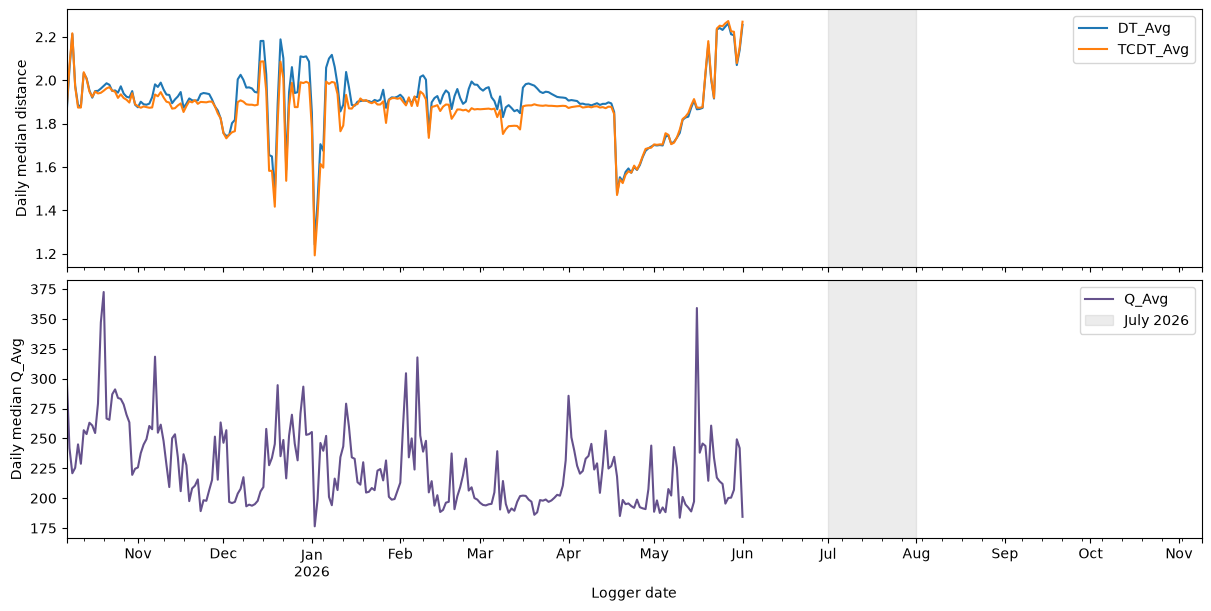

In [ ]:
distances = ["DT_Avg", "TCDT_Avg"]
distance = data[distances].where(data[distances].gt(0))
quality = data.Q_Avg
channels = pd.concat([distance, quality], axis=1)

coverage = []
for name in channels:
    valid = channels[name].dropna()
    coverage.append({
        "Channel": name, "First valid": valid.index.min(), "Last valid": valid.index.max(),
        "Valid readings": valid.size, "Missing in July 2026": channels.loc["2026-07", name].isna().sum(),
        "Valid in July 2026": channels.loc["2026-07", name].count(),
        "Median": valid.median(),
    })
coverage_table = pd.DataFrame(coverage).set_index("Channel")
display(coverage_table.round({"Median": 3}))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
distance.resample("D").median().plot(ax=axes[0])
quality.resample("D").median().plot(ax=axes[1], color="#65518c")
axes[0].set_ylabel("Daily median distance")
axes[1].set(ylabel="Daily median Q_Avg", xlabel="Logger date")
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-07-01"), pd.Timestamp("2026-08-01"),
               color="grey", alpha=0.15, label="July 2026")
axes[1].legend()
plt.show()

## Identify the temperature-corrected channel

Test whether multiplying `DT_Avg` by √((air temperature in °C + 273.15) / 273.15)
reproduces `TCDT_Avg`. Close agreement supports interpreting the two channels as raw
and temperature-corrected distances to the same target. A shorter corrected distance
implies a higher surface under the sensor.

,Distance units
Paired readings,33981.000000
Median residual,0.000006
RMSE,0.000408
95th percentile absolute residual,0.000776


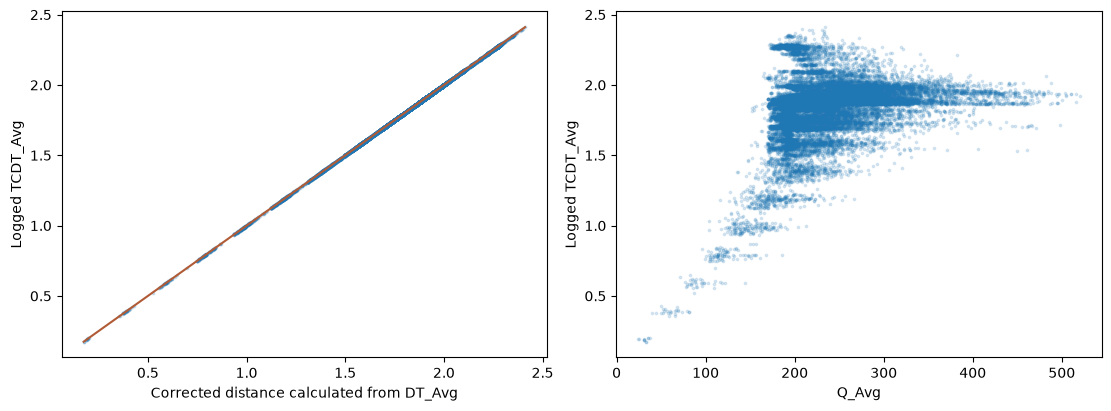

In [ ]:
predicted = distance.DT_Avg * np.sqrt((data.AirTC_Avg + 273.15) / 273.15)
residual = (distance.TCDT_Avg - predicted).dropna()
display(pd.Series({
    "Paired readings": residual.size,
    "Median residual": residual.median(),
    "RMSE": np.sqrt(residual.pow(2).mean()),
    "95th percentile absolute residual": residual.abs().quantile(.95),
}, name="Distance units").round(6).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
common = residual.index
axes[0].scatter(predicted.loc[common], distance.TCDT_Avg.loc[common], s=3, alpha=.2)
limits = [predicted.min(), predicted.max()]
axes[0].plot(limits, limits, color="#b05b36")
axes[0].set(xlabel="Corrected distance calculated from DT_Avg",
            ylabel="Logged TCDT_Avg")
axes[1].scatter(quality, distance.TCDT_Avg, s=3, alpha=.15)
axes[1].set(xlabel="Q_Avg", ylabel="Logged TCDT_Avg")
plt.show()

## Test possible snow-free reference distances

July contains no usable distance readings. Late May and early June contain the longest
sustained high-distance episode near the end of the record. Test it as a candidate,
alongside an earlier October window for comparison. The daily 10th–90th percentile
band and the sensitivity to the selected dates help show whether the target settles
to a repeatable distance. A large reading can reflect bare ground or a different
acoustic return. These windows have no independent snow-free confirmation.

The calculation is **candidate snow depth = reference distance − corrected distance**.
Negative values stay visible so they can flag a reference that is too short or bad
returns. The plot uses daily medians and leaves days with fewer than 36 ten-minute
readings blank.

,Start,End,Readings,P10,Candidate reference,P90,Full record below zero (%)
Window,,,,,,,
Early October,2025-10-08,2025-10-10,432,1.874,2.104,2.287,4.538
Late May,2026-05-23,2026-05-29,1008,1.998,2.262,2.278,2.375
June 1 (partial day),2026-06-01,2026-06-01,65,2.105,2.270,2.279,1.795
July (snow-free hypothesis),2026-07-01,2026-07-31,0,NaN,NaN,NaN,NaN


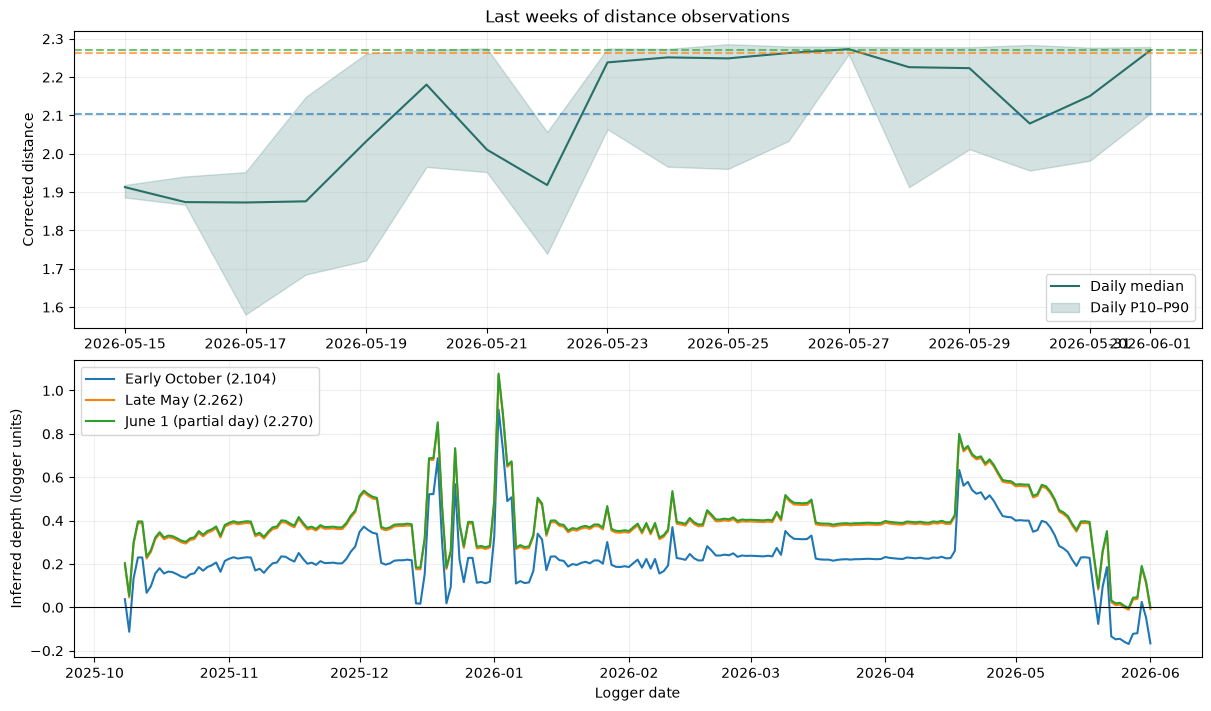

In [ ]:
windows = {
    "Early October": ("2025-10-08", "2025-10-10"),
    "Late May": ("2026-05-23", "2026-05-29"),
    "June 1 (partial day)": ("2026-06-01", "2026-06-01"),
    "July (snow-free hypothesis)": ("2026-07-01", "2026-07-31"),
}
tc = distance.TCDT_Avg
summary = []
for label, (start, stop) in windows.items():
    window = tc.loc[start:stop].dropna()
    reference = window.median()
    summary.append({
        "Window": label, "Start": start, "End": stop, "Readings": window.size,
        "P10": window.quantile(.1), "Candidate reference": reference,
        "P90": window.quantile(.9),
        "Full record below zero (%)": tc.dropna().gt(reference).mean() * 100
        if window.size else np.nan,
    })
candidates = pd.DataFrame(summary).set_index("Window")
display(candidates.round(3))

days = tc.resample("D")
median = days.median().where(days.count().ge(36))
low = days.quantile(.1).where(median.notna())
high = days.quantile(.9).where(median.notna())
melt = slice("2026-05-15", "2026-06-05")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
axes[0].plot(median.loc[melt], color="#276f67", label="Daily median")
axes[0].fill_between(median.loc[melt].index, low.loc[melt], high.loc[melt],
                     color="#276f67", alpha=.2, label="Daily P10–P90")
axes[0].set(ylabel="Corrected distance", title="Last weeks of distance observations")
for label, reference in candidates["Candidate reference"].dropna().items():
    line, = axes[1].plot(reference - median, label=f"{label} ({reference:.3f})")
    axes[0].axhline(reference, color=line.get_color(), linestyle="--", alpha=.65)
axes[1].axhline(0, color="black", linewidth=.8)
axes[1].set(ylabel="Inferred depth (logger units)", xlabel="Logger date")
for ax in axes:
    ax.legend(loc="best")
    ax.grid(alpha=.2)
plt.show()

The temperature correction can be checked directly against the logger data. A
calibrated depth still depends on the snow-free distance and confidence that the sensor
was returning the ground or snow surface. A dated bare-ground photo or the installation
height would help choose a reference. Candidate depths here are for inspection and
stay outside the SNOWPACK inputs.

## Figure for Miaja

A standalone summary of the distance record and the late-May reference test. This cell
exports one PNG to `figures/` for attaching to an email.

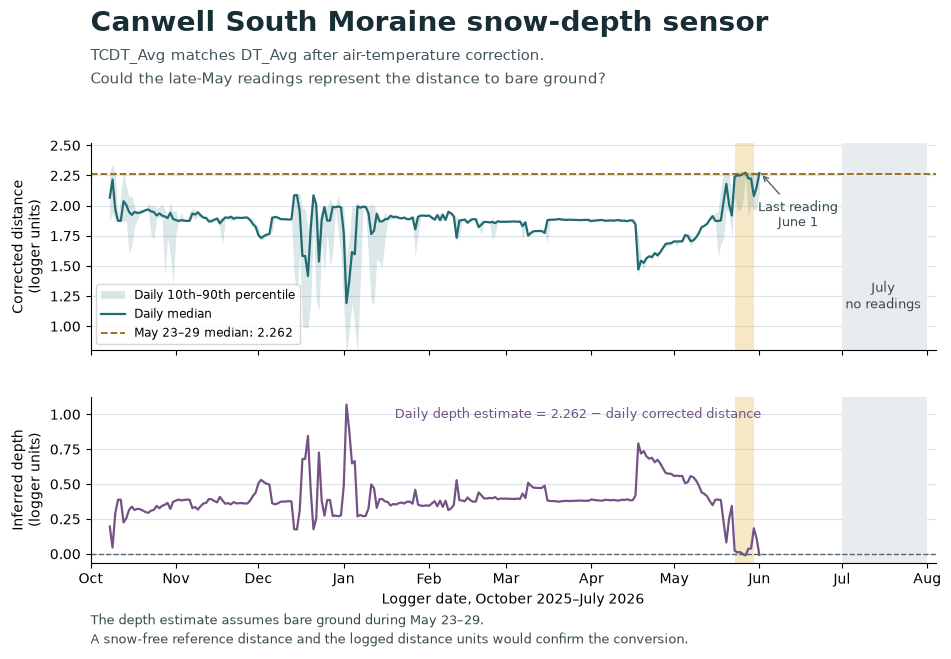

In [ ]:
import matplotlib.dates as mdates

reference = candidates.loc["Late May", "Candidate reference"]
ref_start = pd.Timestamp("2026-05-23")
ref_end = pd.Timestamp("2026-05-30")
last_reading = tc.last_valid_index()
july_start, july_end = pd.Timestamp("2026-07-01"), pd.Timestamp("2026-08-01")
figure_end = pd.Timestamp("2026-08-04")

fig, (ax, depth_ax) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                   gridspec_kw={"height_ratios": [1.25, 1]})
fig.subplots_adjust(left=.115, right=.96, top=.78, bottom=.18, hspace=.25)
fig.text(.115, .94, "Canwell South Moraine snow-depth sensor", fontsize=20,
         fontweight="bold", color="#182d34")
fig.text(.115, .865,
         "TCDT_Avg matches DT_Avg after air-temperature correction.\n"
         "Could the late-May readings represent the distance to bare ground?",
         fontsize=11, color="#43565e", linespacing=1.5)

teal, purple = "#216b70", "#755286"
for axis in (ax, depth_ax):
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#dbe3e6")
    axis.spines[["top", "right"]].set_visible(False)
    axis.axvspan(ref_start, ref_end, color="#e7bd62", alpha=.36, linewidth=0)
    axis.axvspan(july_start, july_end, color="#e8ecef", linewidth=0)
    axis.set_xlim(median.first_valid_index() - pd.Timedelta(days=7), figure_end)

ax.fill_between(median.index, low, high, color=teal, alpha=.16, linewidth=0,
                label="Daily 10th–90th percentile")
ax.plot(median, color=teal, linewidth=1.6, label="Daily median")
ax.axhline(reference, color="#956619", linestyle="--", linewidth=1.3,
           label=f"May 23–29 median: {reference:.3f}")
ax.set_ylabel("Corrected distance\n(logger units)")
ax.set_ylim(.8, 2.52)
ax.legend(loc="lower left", fontsize=8.5, frameon=True, ncols=1)
ax.annotate("Last reading\nJune 1", xy=(last_reading, median.loc[last_reading.normalize()]),
            xytext=(pd.Timestamp("2026-06-15"), 1.83),
            arrowprops={"arrowstyle": "->", "color": "#53666c"},
            ha="center", fontsize=9, color="#374a50")
ax.text(pd.Timestamp("2026-07-16"), 1.25, "July\nno readings",
        ha="center", va="center", fontsize=9, color="#374a50")

depth_ax.plot(reference - median, color=purple, linewidth=1.6)
depth_ax.axhline(0, color="#53666c", linestyle="--", linewidth=1)
depth_ax.set_ylabel("Inferred depth\n(logger units)")
depth_ax.xaxis.set_major_locator(mdates.MonthLocator())
depth_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
depth_ax.set_xlabel("Logger date, October 2025–July 2026")
depth_ax.text(.36, .94, f"Daily depth estimate = {reference:.3f} − daily corrected distance",
              transform=depth_ax.transAxes, va="top", fontsize=9, color=purple)

fig.text(.115, .065,
         "The depth estimate assumes bare ground during May 23–29.\n"
         "A snow-free reference distance and the logged distance units would confirm the conversion.",
         fontsize=9.5, color="#374a50", linespacing=1.45)

figure_path = root / "figures" / "canwell_snow_depth_sensor_summary.png"
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=220, facecolor="white")
plt.show()